## Project setup
(From lab)


In [7]:
!pip install ultralytics
import ultralytics
ultralytics.checks()

#we need to install roboflow because that's where our datasets are from.
%pip install roboflow

Ultralytics 8.4.194 🚀 Python-3.9.6 torch-2.8.0 CPU (Apple M4 Max)
Setup complete ✅ (14 CPUs, 36.0 GB RAM, 168.9/926.4 GB disk)
Note: you may need to restart the kernel to use updated packages.


## Dataset setup

For our dataset, we have 3 sources:

We'll have 7 classes: Coal, Iron, Redstone, Gold, Emerald, Lapis, Diamond.

We're using 3 datasets, and we need to merge them. I can't just put in "dataset_path...{}".

This means we're going to need to merge all the datasets into one, which we can run through. Since they all use slight deviations in class names, we're going to need to remap them into our 7 classes.

To do this, I'll use Claude's help, since this is outside of our rubric.

In [ ]:
import random
import shutil
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import yaml
from PIL import Image, ImageDraw

ROOT = Path.cwd()
RAW_DIR = ROOT / 'datasets' / 'raw'
MERGED_DIR = ROOT / 'datasets' / 'merged'

CLASSES = ['coal ore', 'diamond ore', 'gold ore', 'lapis ore', 'redstone ore', 'iron ore', 'emerald ore']

#
DATASETS = [
    {'name': 'oblig10', 'workspace': 'oblig10', 'project': 'minecraft-ore-detection-20pzg-xejw6', 'version': 2,
     'splits': {'train': 'train', 'valid': 'valid', 'test': 'test'}},
    {'name': 'blocks', 'workspace': 'main-data', 'project': 'minecraft-blocks', 'version': 1,
     'splits': {'train': 'train', 'valid': 'valid', 'test': 'test'}},
    {'name': '360', 'workspace': 'aasmaa-alibhai', 'project': '360-3wqmv', 'version': 1,
     'splits': {'train': 'test'}},
]

Downloading the datasets from Roboflow. 
Since one of my groupmates also uploaded our dataset to Roboflow, we can grab it too!

In [9]:
from roboflow import Roboflow

rf = Roboflow(api_key="YOUR_ROBOFLOW_API_KEY")

project = rf.workspace("main-data").project("minecraft-blocks")
project.version(1).download("yolov8", location=str(RAW_DIR / "blocks"))

project = rf.workspace("oblig10").project("minecraft-ore-detection-20pzg-xejw6")
project.version(2).download("yolov8", location=str(RAW_DIR / "oblig10"))

project = rf.workspace("aasmaa-alibhai").project("360-3wqmv")
project.version(1).download("yolov8", location=str(RAW_DIR / "360"))

#had help from Claude to write this download code.

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /Users/caleb/Documents/github/minecraft-ore-yolo/datasets/raw/blocks in yolov8:: 100%|██████████| 2276/2276 [00:00<00:00, 9429.97it/s]

loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to /Users/caleb/Documents/github/minecraft-ore-yolo/datasets/raw/oblig10 in yolov8:: 100%|██████████| 6299/6299 [00:01<00:00, 5833.76it/s]


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /Users/caleb/Documents/github/minecraft-ore-yolo/datasets/raw/360 in yolov8:: 100%|██████████| 253/253 [00:00<00:00, 7819.49it/s]


Now that we've downloaded our datasets, we need to translate them so we can map them into our 7 classes. 

The reason that we have 3 datasets is because, the original biggest dataset we chose only had 5 classes. We wanted to have 7 classes, so we found another dataset with overlap with the original dataset. The final dataset is our own 125 images we uploaded and labelled.

I had Claude help me write the code to merge the datasets since it's not covered in the labs.

In [18]:
#setting up our new merged dataset definitions

def to_master_id(name):
    matches = [i for i, cls in enumerate(CLASSES) if cls.split()[0] in name.lower()]
    if len(matches) != 1:
        raise ValueError(f'Cannot match class name {name!r} to exactly one of {CLASSES}')
    return matches[0]


def build_remap(dataset_dir):
    names = yaml.safe_load((dataset_dir / 'data.yaml').read_text())['names']
    if isinstance(names, dict):
        names = [names[i] for i in sorted(names)]
    return {i: to_master_id(name) for i, name in enumerate(names)}, names


#verifying how they will get merged via print
for d in DATASETS:
    remap, names = build_remap(RAW_DIR / d['name'])
    print(f"\n{d['name']}")
    for old_id, name in enumerate(names):
        print(f'  {old_id}: {name:<25} -> {remap[old_id]}: {CLASSES[remap[old_id]]}')


oblig10
  0: Deepslate Diamond Ore     -> 1: diamond ore
  1: Deepslate Gold Ore        -> 2: gold ore
  2: Deepslate Iron Ore        -> 5: iron ore
  3: Deepslate RedstoneOre     -> 4: redstone ore
  4: Iron Ore                  -> 5: iron ore

blocks
  0: coal                      -> 0: coal ore
  1: diamond                   -> 1: diamond ore
  2: emerald                   -> 6: emerald ore
  3: gold                      -> 2: gold ore
  4: iron                      -> 5: iron ore
  5: lapis                     -> 3: lapis ore
  6: redstone                  -> 4: redstone ore

360
  0: coal ore                  -> 0: coal ore
  1: diamond ore               -> 1: diamond ore
  2: emerald ore               -> 6: emerald ore
  3: gold ore                  -> 2: gold ore
  4: iron ore                  -> 5: iron ore
  5: lapis ore                 -> 3: lapis ore
  6: redstone ore              -> 4: redstone ore


In [19]:
def merge_dataset(d):
    source = RAW_DIR / d['name']
    remap, _ = build_remap(source)
    for source_split, target_split in d['splits'].items():
        images_dir = source / source_split / 'images'
        labels_dir = source / source_split / 'labels'
        if not images_dir.exists():
            print(f"  {d['name']}/{source_split}: no images, skipped")
            continue

        out_images = MERGED_DIR / target_split / 'images'
        out_labels = MERGED_DIR / target_split / 'labels'
        out_images.mkdir(parents=True, exist_ok=True)
        out_labels.mkdir(parents=True, exist_ok=True)

        count = 0
        for image_path in sorted(images_dir.iterdir()):
            new_name = f"{d['name']}_{image_path.name}"
            shutil.copy(image_path, out_images / new_name)
            count += 1

            label_path = labels_dir / f'{image_path.stem}.txt'
            if not label_path.exists():
                continue
            new_lines = []
            for line in label_path.read_text().splitlines():
                parts = line.split()
                if not parts:
                    continue
                if len(parts) != 5:
                    xs = [float(v) for v in parts[1::2]]
                    ys = [float(v) for v in parts[2::2]]
                    parts = [parts[0],
                             str((min(xs) + max(xs)) / 2),
                             str((min(ys) + max(ys)) / 2),
                             str(max(xs) - min(xs)),
                             str(max(ys) - min(ys))]
                parts[0] = str(remap[int(parts[0])])
                new_lines.append(' '.join(parts))
            (out_labels / f'{Path(new_name).stem}.txt').write_text('\n'.join(new_lines) + '\n' if new_lines else '')
        print(f"  {d['name']}/{source_split} -> {target_split}: {count} images")


if MERGED_DIR.exists():
    shutil.rmtree(MERGED_DIR)
for d in DATASETS:
    merge_dataset(d)

data_yaml = {'path': str(MERGED_DIR), 'train': 'train/images', 'val': 'valid/images', 'names': dict(enumerate(CLASSES))}
if (MERGED_DIR / 'test' / 'images').exists():
    data_yaml['test'] = 'test/images'
(MERGED_DIR / 'data.yaml').write_text(yaml.safe_dump(data_yaml, sort_keys=False))
print(f"\nWrote {MERGED_DIR / 'data.yaml'}")

  oblig10/train -> train: 2906 images
  oblig10/valid -> valid: 122 images
  oblig10/test -> test: 119 images
  blocks/train -> train: 983 images
  blocks/valid -> valid: 100 images
  blocks/test -> test: 49 images
  360/train -> test: 125 images

Wrote /Users/caleb/Documents/github/minecraft-ore-yolo/datasets/merged/data.yaml


In [20]:
def count_boxes(split):
    counts = Counter()
    for label_path in (MERGED_DIR / split / 'labels').glob('*.txt'):
        for line in label_path.read_text().splitlines():
            counts[int(line.split()[0])] += 1
    return counts


splits = [s for s in ('train', 'valid', 'test') if (MERGED_DIR / s).exists()]
all_counts = {s: count_boxes(s) for s in splits}
print(f"{'class':<15}" + ''.join(f'{s:>8}' for s in splits))
for i, cls in enumerate(CLASSES):
    print(f'{cls:<15}' + ''.join(f'{all_counts[s][i]:>8}' for s in splits))

class             train   valid    test
coal ore            534      35      80
diamond ore        1307      47      56
gold ore           1880      82     106
lapis ore           159      29      20
redstone ore       2501     130     114
iron ore           4482     194     233
emerald ore         177      23      25


## Training data

Now that our dataset is merged (merge_dataset) and we have both training and test splits, we can start to begin training our YOLO model. We started with 3 epochs because this is what we started with in the lab code.

Ultralytics 8.4.194 🚀 Python-3.9.6 torch-2.8.0 CPU (Apple M4 Max)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datasets/merged/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-4, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask

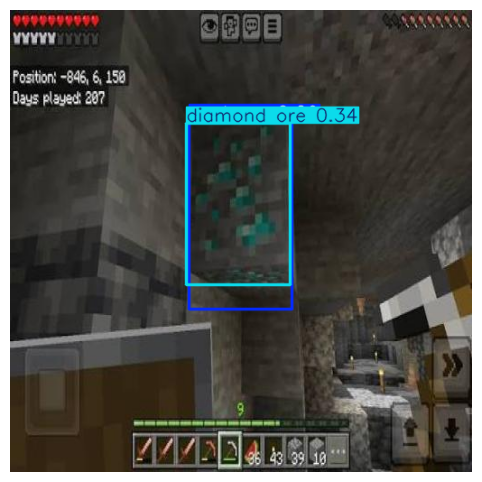

In [25]:
# Code snippets from week 6 lab, classification
from ultralytics import YOLO

model = YOLO('yolov8n.pt') 

##model training
model.train(data='datasets/merged/data.yaml', epochs=3)  # just the most basic lab hyperparameters

test_images = list((MERGED_DIR / 'test' / 'images').glob('*.jpg'))
image = random.choice(test_images)
results = model(image)

plt.figure(figsize=(10, 6))
plt.imshow(results[0].plot()[..., ::-1])
plt.axis('off')
plt.show()

Test 1 only ran 3 epochs which was an insufficient amount of epochs to produce somewhat consistent results. Since we only ran 3 runs, it looked like the improvements across each run skyrocketed (in terms of mAP50, precision, and recall).

To calibrate a better baseline with more consistent results, we will run a 10 epoch test next (no other hyperparameters or changes). 

In [ ]:
# Code snippets from week 6 lab, classification
from ultralytics import YOLO

model = YOLO('yolov8n.pt') 

##model training
model.train(data='datasets/merged/data.yaml', device='mps', epochs=10, name='epochs_10')  # just the most basic lab hyperparameters

test_images = list((MERGED_DIR / 'test' / 'images').glob('*.jpg'))
image = random.choice(test_images)
results = model(image)

plt.figure(figsize=(10, 6))
plt.imshow(results[0].plot()[..., ::-1])
plt.axis('off')
plt.show()

## Hyperparameter tuning

Each member of the group will tune one hyperparameter, training models on a low, a medium, and a high value in order to evaluate how the model responds to increasing or decreasing said hyperparameter.

Hyperparameter list:

Imgsz
The image size the model trains on. 
Lowest scores from our baseline test were across precision and recall. This probably means that the images the model trains on and validates against just aren’t high enough resolution.
Minecraft is a block game made up of pixels, increasing the image size will greatly help with lower resolution blocks, which pixels will be enlarged.
Runs: 416, 800, 1024

Scale
Random scaling augmentation range. Helps model detect objects at different sizes
Hopefully will help identify ores that are farther away / in the background
From: https://docs.ultralytics.com/guides/hyperparameter-tuning
Runs: 0.0, 0.25, 0.9

HSV
Random value (brightness) augmentation range. Helps model handle different exposure levels
Hopefully will help identify ores in dark caves, or underground.
From: https://docs.ultralytics.com/guides/hyperparameter-tuning
Runs: 0.0, 0.2, 0.7

Learning rate
Initial learning rate at the start of training. Lower values provide more stable training but slower convergence
For our final hyperparameter, we chose learning rate since it changes the way that the model learns. Our previous 3 hyperparameters changed the way the images looked, and the results we got didn’t yield any substantial improvements past ~0.8 (in precision, recall, etc.)
From: https://docs.ultralytics.com/guides/hyperparameter-tuning
Runs: 0.0003, 0.002, 0.005


For a more in-depth breakdown of the hyperparameter results, please refer to our report.

### Moving to Google Colab

So my laptop almost crashed trying to train the baseline on 10 epochs. To mitigate this, I moved to Google Colab to conduct my hyperparameter testing.

I had Claude help me set up the following code (In order to sync my colab runs with my Google Drive.)
- The merged dataset is unzipped from Google Drive into the Colab machine (`/content`), because Colab starts with an empty disk.
- Runs are saved to Google Drive (`project=str(RUNS_DIR)`), so a Colab disconnect can't lose them.
- `device` isn't set: Colab's GPU is picked automatically.

The training settings are otherwise identical to the baseline: `yolov8n.pt`, 10 epochs, `imgsz=640`, and Ultralytics defaults for everything else.

In [ ]:
# Colab setup: run this once per Colab session, before any of the runs below.
import random
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import yaml
from google.colab import drive
from ultralytics import YOLO

ROOT = Path('/content')
MERGED_DIR = ROOT / 'datasets' / 'merged'

# Load the merged dataset from Drive, and save runs back to Drive.
drive.mount('/content/drive')
DRIVE_DIR = Path('/content/drive/MyDrive/minecraft-ore-yolo-folder')
RUNS_DIR = DRIVE_DIR / 'runs'
if not (MERGED_DIR / 'data.yaml').exists():
    shutil.unpack_archive(DRIVE_DIR / 'merged.zip', MERGED_DIR)

# data.yaml still points to the Mac folder, so point it at the Colab copy.
cfg = yaml.safe_load((MERGED_DIR / 'data.yaml').read_text())
cfg['path'] = str(MERGED_DIR)
(MERGED_DIR / 'data.yaml').write_text(yaml.safe_dump(cfg, sort_keys=False))
DATA = str(MERGED_DIR / 'data.yaml')

### How each hyperparameter is tested

Each hyperparameter is tested at 3 values. Instead of writing three separate training cells per hyperparameter, I wanted to use a for loop to run them, and store the runs in an array. That way I didn't need to come back and requeue a new run each time an old one finished. From IAT359/459, etc., I knew about for loops, but didn't really know how to make one work for this specific process.

I used Claude Code to help me set this function up to basically take a param (the array of parameters), and then pass them into this code. Baseline is preserved.


For every run, `run_sweep`:

1. Starts from fresh `yolov8n.pt` weights (not the previous run's weights).
2. Trains with the baseline settings (`BASELINE`), overriding only the setting listed for that run.
3. Saves the run to Google Drive under its name (because it's running on Colab)
4. Shows its prediction on the same test image, so the previews can be compared.
5. Prints a precision / recall / mAP / F1 table for the 3 runs at the end. (Since this is what I was using to evaluate runs quickly)

In [ ]:
# Baseline settings shared by every run. Anything not listed uses the Ultralytics default.
BASELINE = {'model': 'yolov8n.pt', 'epochs': 10, 'imgsz': 640}

# One test image shared by every run, so the predictions are comparable.
TEST_IMAGE = random.choice(list((MERGED_DIR / 'test' / 'images').glob('*.jpg')))


def run_sweep(runs):
    """Train one model per entry in `runs`, each changing only the settings it lists."""
    summary = []
    for run in runs:
        settings = {**BASELINE, **run}          # baseline, then this run's change
        weights = settings.pop('model')
        print(f"\n===== {settings['name']} =====")
        try:
            model = YOLO(weights)               # fresh pretrained weights every run
            metrics = model.train(data=DATA, project=str(RUNS_DIR), **settings)

            r = metrics.results_dict
            p, rec = r['metrics/precision(B)'], r['metrics/recall(B)']
            summary.append({
                'run': settings['name'],
                'precision': p,
                'recall': rec,
                'f1': 2 * p * rec / (p + rec),
                'mAP50': r['metrics/mAP50(B)'],
                'mAP50-95': r['metrics/mAP50-95(B)'],
            })

            # predict at the same imgsz the model was trained on
            results = model(TEST_IMAGE, imgsz=settings['imgsz'])
            plt.figure(figsize=(10, 6))
            plt.imshow(results[0].plot()[..., ::-1])
            plt.title(settings['name'])
            plt.axis('off')
            plt.show()
        except Exception as e:
            print(f"{settings['name']} failed: {e}")   # one failed run doesn't stop the rest

    for s in summary:
        print(f"{s['run']:<14} P={s['precision']:.3f}  R={s['recall']:.3f}  F1={s['f1']:.3f}  "
              f"mAP50={s['mAP50']:.3f}  mAP50-95={s['mAP50-95']:.3f}")
    return summary

### 1. Image size (`imgsz`)

Baseline: `imgsz=640`. Tested: 416, 800, 1024.

In [ ]:
RUNS = [
    {'name': 'imgsz-416',  'imgsz': 416},
    {'name': 'imgsz-800',  'imgsz': 800},
    {'name': 'imgsz-1024', 'imgsz': 1024},
]
imgsz_results = run_sweep(RUNS)

Results (final epoch, validation set):

| Run | mAP50 | Precision | Recall | F1 |
|---|---|---|---|---|
| Baseline (epochs_10) | 0.80 | 0.75 | 0.77 | 0.76 |
| imgsz-416 | 0.80 | 0.83 | 0.71 | 0.76 |
| imgsz-800 | 0.82 | 0.74 | 0.81 | 0.77 |
| imgsz-1024 | 0.80 | 0.72 | 0.78 | 0.75 |

### 2. Scale augmentation (`scale`)

Baseline: `scale=0.5`.
Tested: 0.0 (no zoom), 0.25, 0.9.

In [ ]:
RUNS = [
    {'name': 'scale-0.0',  'scale': 0.0},
    {'name': 'scale-0.25', 'scale': 0.25},
    {'name': 'scale-0.9',  'scale': 0.9},
]
scale_results = run_sweep(RUNS)

Results (final epoch, validation set):

| Run | mAP50 | Precision | Recall | F1 |
|---|---|---|---|---|
| Baseline (epochs_10) | 0.80 | 0.75 | 0.77 | 0.76 |
| scale-0.0 | 0.79 | 0.77 | 0.79 | 0.78 |
| scale-0.25 | 0.82 | 0.79 | 0.76 | 0.78 |
| scale-0.9 | 0.81 | 0.75 | 0.77 | 0.76 |

### 3. Brightness augmentation (`hsv_v`)

Baseline: `hsv_v=0.4`. Tested: 0.0 (no brightness change), 0.2, 0.7.

In [ ]:
RUNS = [
    {'name': 'hsv-v-0.0', 'hsv_v': 0.0},
    {'name': 'hsv-v-0.2', 'hsv_v': 0.2},
    {'name': 'hsv-v-0.7', 'hsv_v': 0.7},
]
hsv_results = run_sweep(RUNS)

Results (final epoch, validation set):

| Run | mAP50 | Precision | Recall | F1 |
|---|---|---|---|---|
| Baseline (epochs_10) | 0.80 | 0.75 | 0.77 | 0.76 |
| hsv-v-0.0 | 0.82 | 0.77 | 0.78 | 0.78 |
| hsv-v-0.2 | 0.82 | 0.77 | 0.75 | 0.76 |
| hsv-v-0.7 | 0.82 | 0.79 | 0.76 | 0.77 |

### 4. Learning rate (`lr0`)

Baseline: `optimizer='auto'`. For a run this short, Ultralytics picks AdamW and chooses its own learning rate (about 0.0009 for 7 classes), and it **ignores** `lr0`. So these runs set `optimizer='AdamW'` explicitly, otherwise `lr0` would have no effect. Tested: 0.0003, 0.002, 0.005.

In [ ]:
RUNS = [
    {'name': 'lr-0.0003', 'optimizer': 'AdamW', 'lr0': 0.0003},
    {'name': 'lr-0.002',  'optimizer': 'AdamW', 'lr0': 0.002},
    {'name': 'lr-0.005',  'optimizer': 'AdamW', 'lr0': 0.005},
]
lr_results = run_sweep(RUNS)

Results (final epoch, validation set):

| Run | mAP50 | Precision | Recall | F1 |
|---|---|---|---|---|
| Baseline (epochs_10) | 0.80 | 0.75 | 0.77 | 0.76 |
| lr-0.0003 | 0.79 | 0.79 | 0.73 | 0.76 |
| lr-0.002 | 0.78 | 0.79 | 0.73 | 0.76 |
| lr-0.005 | 0.73 | 0.73 | 0.68 | 0.70 |

## Final tuned model

Combines the best value from each hyperparameter test, using the same baseline otherwise (`yolov8n.pt`, 10 epochs):

| Hyperparameter | Baseline | Final |
|---|---|---|
| `imgsz` | 640 | **800** |
| `scale` | 0.5 | **0.25** |
| `hsv_v` | 0.4 | **0.2** |
| learning rate | auto | **auto** (every manual `lr0` scored lower) |

In [ ]:
final_results = run_sweep([
    {'name': 'combined-best', 'imgsz': 800, 'scale': 0.25, 'hsv_v': 0.2},
])

Results (final epoch, validation set):

| Run | mAP50 | Precision | Recall | F1 |
|---|---|---|---|---|
| Baseline (epochs_10) | 0.80 | 0.75 | 0.77 | 0.76 |
| imgsz-800 (best single change) | 0.82 | 0.74 | 0.81 | 0.77 |
| **combined-best** | **0.83** | **0.77** | **0.77** | **0.77** |

mAP50-95 stayed at 0.47, the same as the baseline.

## Test-set evaluation

Every score above comes from the **validation** set. Training uses those images to pick the best epoch, so they have indirectly shaped the model. The **test** set (293 images, including all 125 of our own screenshots) was never used during training or tuning, so scoring the final model on it once gives an honest measure of how it performs on new images.

This only scores the images, it doesn't train. The run folder (`combined-best-test`) also saves `val_batch*_labels.jpg` next to `val_batch*_pred.jpg`: the real boxes vs. the model's predictions on test images, showing correct and incorrect detections. (YOLO names them `val_batch` even when scoring the test split.)

In [ ]:
# Test-set evaluation: score the final model once on images it has never seen
best = YOLO(str(RUNS_DIR / 'combined-best' / 'weights' / 'best.pt'))
metrics = best.val(
    data=DATA,
    split='test',          # the test images, not validation
    imgsz=800,             # same size the model was trained at
    project=str(RUNS_DIR),
    name='combined-best-test',
)

p, r = metrics.box.mp, metrics.box.mr
print(f"TEST  mAP50={metrics.box.map50:.3f}  mAP50-95={metrics.box.map:.3f}  "
      f"P={p:.3f}  R={r:.3f}  F1={2*p*r/(p+r):.3f}")

# mAP50-95 for each ore (stricter than mAP50, so lower)
for i, name in best.names.items():
    print(f"{name:<14} mAP50-95={metrics.box.maps[i]:.3f}")

Results on the full test set (293 images):

| Set | mAP50 | mAP50-95 | Precision | Recall | F1 |
|---|---|---|---|---|---|
| Validation (from training) | 0.83 | 0.47 | 0.77 | 0.77 | 0.77 |
| **Test** | **0.42** | **0.23** | **0.49** | **0.54** | **0.52** |

The test score is much lower than validation. The test set mixes two kinds of images, so the next cell scores them separately.

### Test set split: our own screenshots vs. the Roboflow images

The validation set only contains Roboflow images, and so does training. Our own 125 screenshots appear **only** in the test set, so the model never saw an image like them. This cell scores the two halves of the test set separately.

In [ ]:
# Score the test set in two halves: our own screenshots vs. the Roboflow images
import yaml

test_imgs = sorted((MERGED_DIR / 'test' / 'images').glob('*'))
groups = {
    'own':      [str(p) for p in test_imgs if p.name.startswith('360_')],
    'roboflow': [str(p) for p in test_imgs if not p.name.startswith('360_')],
}

for name, files in groups.items():
    lst = MERGED_DIR / f'test_{name}.txt'
    lst.write_text('\n'.join(files))
    cfg = yaml.safe_load((MERGED_DIR / 'data.yaml').read_text())
    cfg['test'] = str(lst)
    cfg_path = MERGED_DIR / f'data_test_{name}.yaml'
    cfg_path.write_text(yaml.safe_dump(cfg, sort_keys=False))

    m = best.val(data=str(cfg_path), split='test', imgsz=800,
                 project=str(RUNS_DIR), name=f'combined-best-test-{name}')
    p, r = m.box.mp, m.box.mr
    print(f"{name:<9} ({len(files)} images)  mAP50={m.box.map50:.3f}  "
          f"P={p:.3f}  R={r:.3f}  F1={2*p*r/(p+r):.3f}")

Results:

| Test images | Images | mAP50 | Precision | Recall | F1 |
|---|---|---|---|---|---|
| Roboflow datasets | 168 | **0.86** | 0.81 | 0.82 | 0.81 |
| Our own screenshots | 125 | **0.12** | 0.21 | 0.27 | 0.24 |

On images like its training data the model does well (even slightly better than on validation). On our own gameplay screenshots it mostly fails. The prediction images for each half are in `runs/detect/combined-best-test-own/` and `runs/detect/combined-best-test-roboflow/` (`val_batch*_labels.jpg` = real boxes, `val_batch*_pred.jpg` = the model's predictions; YOLO names them `val_batch` even when scoring the test split).

## Appendix: extra runs

Just because this was kinda cool, and I wanted to see and test more individual hyperparameters, I ran the following for testing purposes. 

- I ran yolov8s. Near the end of our hyperparameter training, our results barely changed across precision, recall, mAP50, etc. (around 0.8). I figured that this might just be because we were using yolov8n, and wanted to try a smarter model for fun. It scored higher than our baseline on mAP50, recall and F1 (precision was about the same)! So I probably should've used it and evaluated before running everything else.
- Epoch-20. Just wanted to see if running more epochs would significantly improve the baseline. It didn't really have much of a result, and around 13-15 epochs the results kinda went stagnant. 


- **`yolov8s`:** the larger YOLOv8 **small** model (about 11M parameters vs 3M for nano).
- **`Epoch-20`:** the baseline trained for 20 epochs instead of 10.

In [ ]:
RUNS = [
    {'name': 'yolov8s',      'model': 'yolov8s.pt'},
    {'name': 'Epoch-20',     'epochs': 20},
]
extra_results = run_sweep(RUNS)

Results (final epoch, validation set):

| Run | mAP50 | Precision | Recall | F1 |
|---|---|---|---|---|
| Baseline (epochs_10) | 0.80 | 0.75 | 0.77 | 0.76 |
| yolov8s | 0.81 | 0.74 | 0.79 | 0.77 |
| Epoch-20 | 0.80 | 0.75 | 0.78 | 0.77 |